# Поиск фотографий по текстовому описанию

Фотохостинг «Со Смыслом» хочет находить фотографии по описанию сцены. Подготовим демонстрационную версию: модель получит признаки изображения и текста и вернёт оценку соответствия от 0 до 1.

Исследуем разметку, исключим контент, связанный с детьми, получим векторы изображений и текста, сравним модели и проверим поиск на новых фотографиях. Используем один нейросетевой фреймворк — PyTorch. Для изображений возьмём предобученную ResNet50, для текста — TF-IDF.

Данные взяты из архива `dsplus_integrated_project_4.zip`. Чтобы выполнить ноутбук в другом окружении, разместите распакованную папку `to_upload` рядом с ним. Нужны pandas, NumPy, matplotlib, scikit-learn, PyTorch, torchvision и Pillow.

## 1. Загрузка и исследовательский анализ данных

In [1]:
# Добавим необходимые библиотеки.
import os
import re
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.set_num_threads(min(8, os.cpu_count() or 1))
thread_limits = threadpool_limits(limits=4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)
print('PyTorch:', torch.__version__)

Устройство: cpu
PyTorch: 2.5.1+cpu


In [2]:
# Загрузим данные.
data_paths = [Path('to_upload'), Path('/datasets/to_upload'), Path('/datasets'),
              Path('../work/image_search/to_upload')]
DATA_DIR = next((p for p in data_paths if (p / 'train_dataset.csv').exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Распакуйте архив: папка to_upload должна быть рядом с ноутбуком.')

train = pd.read_csv(DATA_DIR / 'train_dataset.csv')
expert = pd.read_csv(DATA_DIR / 'ExpertAnnotations.tsv', sep='\t', header=None,
                     names=['image', 'query_id', 'expert_1', 'expert_2', 'expert_3'])
crowd = pd.read_csv(DATA_DIR / 'CrowdAnnotations.tsv', sep='\t', header=None,
                    names=['image', 'query_id', 'crowd_score', 'yes', 'no'])
test_queries = pd.read_csv(DATA_DIR / 'test_queries.csv', sep='|', index_col=0)
test_images = pd.read_csv(DATA_DIR / 'test_images.csv')

tables = {'Описания': train, 'Эксперты': expert, 'Крауд': crowd,
          'Тестовые запросы': test_queries, 'Тестовые изображения': test_images}
overview = pd.DataFrame([
    {'Таблица': name, 'Строки': len(frame), 'Пропуски': int(frame.isna().sum().sum()),
     'Дубликаты': int(frame.duplicated().sum())}
    for name, frame in tables.items()
])
display(overview)
display(train.head())
display(expert.head())
display(crowd.head())
display(test_queries.head())

for name, frame in tables.items():
    if frame.isna().any().any():
        raise ValueError('Обнаружены пропуски: ' + name)
    frame.drop_duplicates(inplace=True)

assert not train.duplicated(['image', 'query_id']).any()
assert not expert.duplicated(['image', 'query_id']).any()
assert not crowd.duplicated(['image', 'query_id']).any()
assert train.groupby('query_id')['query_text'].nunique().max() == 1
assert set(train.image).isdisjoint(set(test_images.image))
assert train.image.map(lambda x: (DATA_DIR / 'train_images' / x).is_file()).all()
assert test_images.image.map(lambda x: (DATA_DIR / 'test_images' / x).is_file()).all()
assert set(test_queries.image).issubset(set(test_images.image))
print('Изображений в обучении:', train.image.nunique())
print('Уникальных описаний:', train.query_id.nunique())
print('Тестовых изображений:', len(test_images))

,Таблица,Строки,Пропуски,Дубликаты
0,Описания,5822,0,0
1,Эксперты,5822,0,0
2,Крауд,47830,0,0
3,Тестовые запросы,500,0,0
4,Тестовые изображения,100,0,0


,image,query_id,query_text
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
1,1262583859_653f1469a9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
2,2447284966_d6bbdb4b6e.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
3,2549968784_39bfbe44f9.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
4,2621415349_ef1a7e73be.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...


,image,query_id,expert_1,expert_2,expert_3
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2


,image,query_id,crowd_score,yes,no
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.0,3,0
1,1056338697_4f7d7ce270.jpg,114051287_dd85625a04.jpg#2,0.0,0,3
2,1056338697_4f7d7ce270.jpg,1427391496_ea512cbe7f.jpg#2,0.0,0,3
3,1056338697_4f7d7ce270.jpg,2073964624_52da3a0fc4.jpg#2,0.0,0,3
4,1056338697_4f7d7ce270.jpg,2083434441_a93bc6306b.jpg#2,0.0,0,3


,query_id,query_text,image
0,1177994172_10d143cb8d.jpg#0,"Two blonde boys , one in a camouflage shirt an...",1177994172_10d143cb8d.jpg
1,1177994172_10d143cb8d.jpg#1,Two boys are squirting water guns at each other .,1177994172_10d143cb8d.jpg
2,1177994172_10d143cb8d.jpg#2,Two boys spraying each other with water,1177994172_10d143cb8d.jpg
3,1177994172_10d143cb8d.jpg#3,Two children wearing jeans squirt water at eac...,1177994172_10d143cb8d.jpg
4,1177994172_10d143cb8d.jpg#4,Two young boys are squirting water at each oth...,1177994172_10d143cb8d.jpg


Изображений в обучении: 1000
Уникальных описаний: 977
Тестовых изображений: 100


Проверка показала: в обучении 1000 изображений и 977 разных описаний, во внешней тестовой галерее — 100 изображений и 500 запросов. Пропусков и полных дубликатов в пяти таблицах нет; изображения обучения и внешней проверки не пересекаются.

В архиве есть таблицы с описаниями, два источника разметки и отдельная тестовая галерея. Файлы оценок не имеют заголовка, поэтому названия колонок заданы вручную. Тестовые запросы прочитаны с разделителем `|`.

Одна строка обучения — пара изображения и описания. Имя изображения в `query_id` указывает на исходную фотографию описания; оно может отличаться от `image` в оцениваемой паре. Это важно для объединения таблиц и фильтрации. Полные дубликаты проверены и удаляются, если они есть; одинаковые изображения с разными запросами не считаются дубликатами.

In [3]:
# Проверим диапазоны и согласованность оценок.
expert_columns = ['expert_1', 'expert_2', 'expert_3']
assert expert[expert_columns].isin([1, 2, 3, 4]).all().all()
assert crowd['crowd_score'].between(0, 1).all()
assert crowd[['yes', 'no']].ge(0).all().all()
assert (crowd['yes'] + crowd['no']).gt(0).all()
calculated_share = crowd['yes'] / (crowd['yes'] + crowd['no'])
assert np.allclose(calculated_share, crowd['crowd_score'])

expert['expert_mean'] = expert[expert_columns].mean(axis=1)
expert['target'] = (expert['expert_mean'] - 1) / 3
expert['expert_spread'] = expert[expert_columns].max(axis=1) - expert[expert_columns].min(axis=1)
display(expert[['expert_mean', 'expert_spread']].describe())
display((crowd['yes'] + crowd['no']).value_counts().sort_index().rename('Число пар'))
print('Полное согласие экспертов:', round(expert.expert_spread.eq(0).mean(), 3))

common = expert.merge(crowd, on=['image', 'query_id'], how='inner', validate='one_to_one')
print('Пар с обоими источниками разметки:', len(common))
print('Корреляция Пирсона:', round(common.target.corr(common.crowd_score), 3))
print('Корреляция Спирмена:', round(common.target.corr(common.crowd_score, method='spearman'), 3))

,expert_mean,expert_spread
count,5822.000000,5822.000000
mean,1.647658,0.445380
std,0.806205,0.551135
min,1.000000,0.000000
25%,1.000000,0.000000
50%,1.333333,0.000000
75%,2.000000,1.000000
max,4.000000,3.000000


3    46780
4      780
5      220
6       50
Name: Число пар, dtype: int64

Полное согласие экспертов: 0.582
Пар с обоими источниками разметки: 2329
Корреляция Пирсона: 0.791
Корреляция Спирмена: 0.715


По всем трём экспертным оценкам полное согласие наблюдается в 58.2% пар. Для 2329 пар есть оба источника разметки. Корреляция Пирсона между нормированным средним экспертов и краудом равна 0.791, Спирмена — 0.715. Доли положительных ответов крауда совпадают с расчётом по числам голосов.

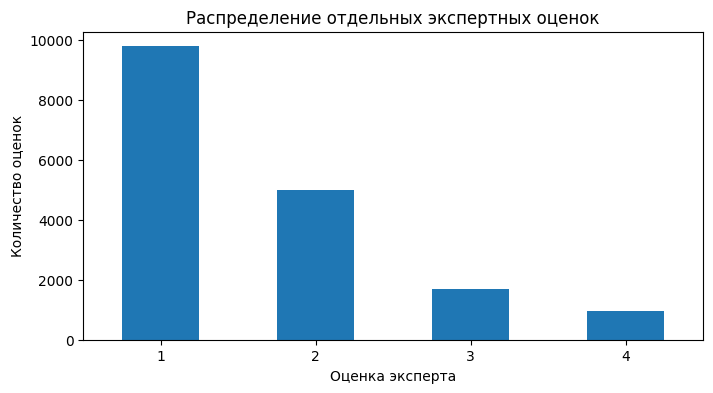

In [4]:
# Посмотрим на оценки экспертов.
plt.figure(figsize=(8, 4))
expert[expert_columns].stack().value_counts().sort_index().plot.bar(rot=0)
plt.title('Распределение отдельных экспертных оценок')
plt.xlabel('Оценка эксперта')
plt.ylabel('Количество оценок')
plt.show()

На графике преобладают низкие оценки: большинство пар не соответствует друг другу или соответствует слабо. Полностью релевантных пар значительно меньше. При таком дисбалансе низкая средняя ошибка сама по себе не гарантирует хороший поиск: модель может почти всегда предсказывать низкую оценку. Поэтому дополнительно проверим качество ранжирования.

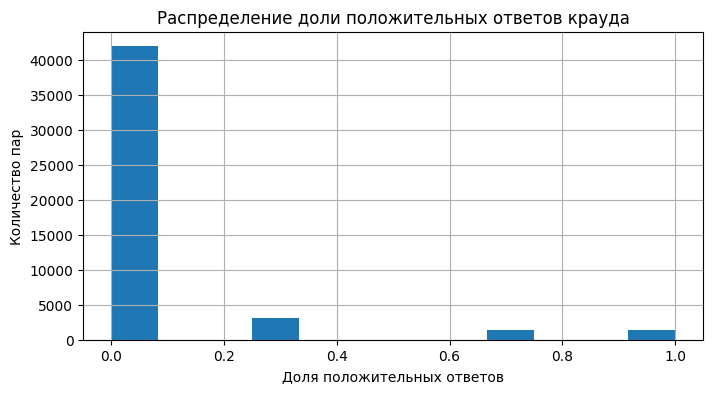

In [5]:
# Посмотрим на оценки краудсорсинга.
plt.figure(figsize=(8, 4))
crowd.crowd_score.hist(bins=12)
plt.title('Распределение доли положительных ответов крауда')
plt.xlabel('Доля положительных ответов')
plt.ylabel('Количество пар')
plt.show()

У крауда тоже много нулевых оценок. Часто пару оценивали всего три человека, поэтому доля ответов меняется крупными шагами. Кроме того, крауд отвечает на бинарный вопрос, а экспертная шкала различает степень соответствия.

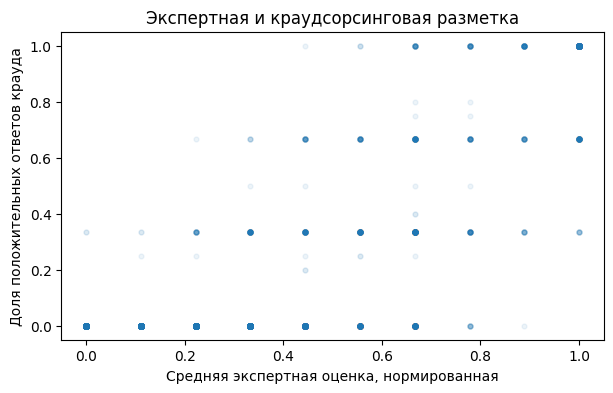

In [6]:
# Сравним источники разметки на общих парах.
plt.figure(figsize=(7, 4))
plt.scatter(common.target, common.crowd_score, alpha=0.08, s=12)
plt.xlabel('Средняя экспертная оценка, нормированная')
plt.ylabel('Доля положительных ответов крауда')
plt.title('Экспертная и краудсорсинговая разметка')
plt.show()

Источники разметки связаны, но не совпадают: для одной нормированной экспертной оценки встречаются разные доли положительных ответов крауда. Для обучения выберем экспертную разметку: именно итоговую оценку экспертов требуется предсказывать в задании.

Агрегируем три оценки средним арифметическим, затем преобразуем шкалу 1–4 в 0–1: `(средняя оценка − 1) / 3`. Среднее сохраняет частичное соответствие и не требует удалять пары, где все эксперты дали разные оценки. Полученное число — оценка соответствия, а не доказанная калиброванная вероятность. Крауд используем для анализа, но не смешиваем с целевым признаком.

## 2. Проверка данных и ограничения поиска

Для PoC применим ограничения из условия задачи. Составим список слов, связанных с детьми и подростками. Если слово встречается в описании, исключим запрос и все пары с исходной фотографией этого описания. Для тестовой галереи также исключим изображение, если хотя бы одно его описание содержит такое слово.

У фильтра есть ограничения: `girl` или `boy` иногда относятся к взрослым, а отсутствие этих слов не доказывает возраст человека. Здесь выбираем консервативное исключение. Для реального сервиса понадобятся проверка изображений и механизм согласий; словарь не обеспечивает юридическую проверку сам по себе.

In [7]:
# Подготовим словарь ограничений.
restricted_words = [
    'baby', 'babies', 'child', 'children', 'kid', 'kids', 'boy', 'boys',
    'girl', 'girls', 'toddler', 'toddlers', 'infant', 'infants', 'teen', 'teens',
    'teenage', 'teenager', 'teenagers', 'schoolboy', 'schoolboys',
    'schoolgirl', 'schoolgirls', 'schoolchildren', 'preschool', 'kindergarten',
    'adolescent', 'adolescents', 'minor', 'minors'
]
restricted_pattern = re.compile(r'\b(?:' + '|'.join(restricted_words) + r')\b', re.I)
age_pattern = re.compile(r'\b(\d{1,2})[ -]+(?:years?[ -]+old|year[ -]+old)\b', re.I)
DISCLAIMER = 'This image is unavailable in your country in compliance with local laws.'

def restricted_query(text):
    text = str(text)
    if restricted_pattern.search(text):
        return True
    return any(int(age) < 16 for age in age_pattern.findall(text))

assert restricted_query('Two children in a park')
assert restricted_query('A 15-year-old person')
assert not restricted_query('A man with a dog')

train['source_image'] = train.query_id.str.split('#').str[0]
unsafe_train = train.query_text.map(restricted_query)
blocked_train = set(train.loc[unsafe_train, 'source_image'])
unsafe_test = test_queries.query_text.map(restricted_query)
blocked_test = set(test_queries.loc[unsafe_test, 'image'])

pairs = train.merge(expert[['image', 'query_id', 'target']],
                    on=['image', 'query_id'], how='inner', validate='one_to_one')
pairs = pairs.loc[
    ~pairs.query_text.map(restricted_query)
    & ~pairs.image.isin(blocked_train)
    & ~pairs.source_image.isin(blocked_train)
].reset_index(drop=True)
safe_test_queries = test_queries.loc[~test_queries.image.isin(blocked_test)].copy()
gallery_names = sorted(set(test_images.image) - blocked_test)

assert not pairs.query_text.map(restricted_query).any()
assert set(pairs.image).isdisjoint(blocked_train)
assert set(gallery_names).isdisjoint(blocked_test)
display(pd.DataFrame({
    'Этап': ['Все экспертные пары', 'Пары после фильтра', 'Все тестовые изображения', 'Безопасная галерея'],
    'Количество': [len(train), len(pairs), len(test_images), len(gallery_names)]
}))
print('Исключено обучающих изображений по собственным описаниям:', len(blocked_train))
print('Исключено тестовых изображений:', len(blocked_test))

,Этап,Количество
0,Все экспертные пары,5822
1,Пары после фильтра,3179
2,Все тестовые изображения,100
3,Безопасная галерея,56


Исключено обучающих изображений по собственным описаниям: 290
Исключено тестовых изображений: 44


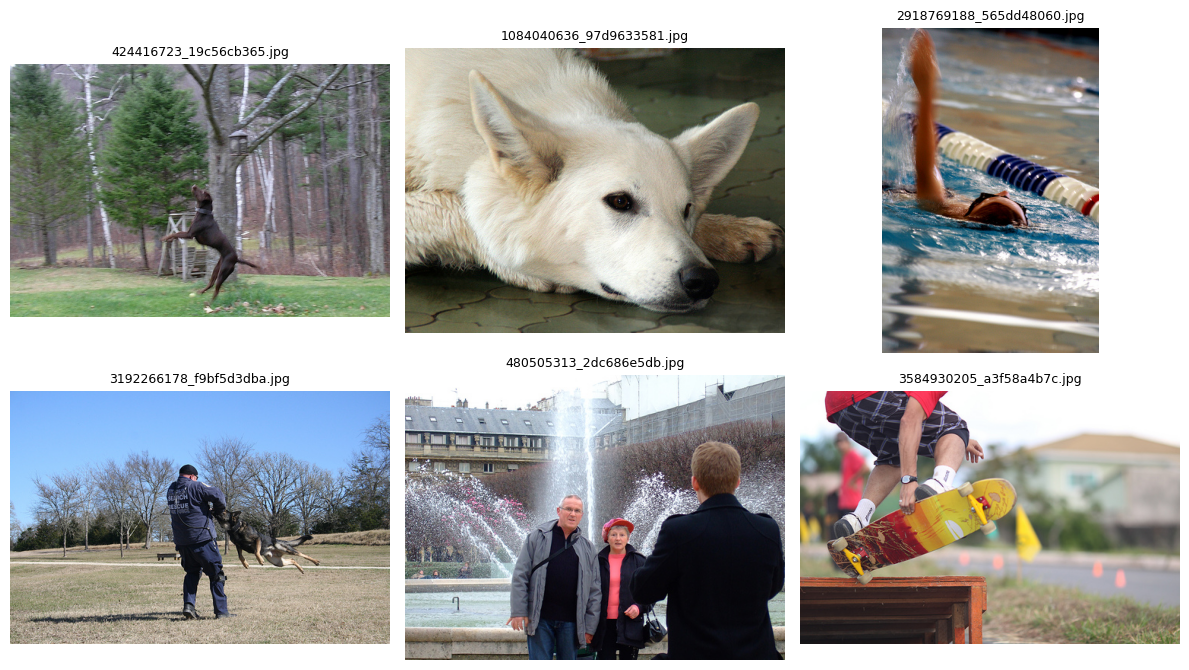

In [8]:
# Посмотрим на несколько оставшихся изображений.
example_names = pairs.image.drop_duplicates().sample(6, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, name in zip(axes.flat, example_names):
    with Image.open(DATA_DIR / 'train_images' / name) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(name, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

На примерах видно, что фотографии отличаются сюжетом, фоном, размером и освещением. Для получения признаков приведём их к одному размеру и используем одинаковую предобработку предобученной ResNet50. Файлы физически не удаляем: исключаем их из используемых таблиц и галереи.

## 3. Векторизация изображений

Используем ResNet50 с весами ImageNet. Удалим последний классификационный слой, оставив глобальный пулинг: каждое изображение будет представлено вектором из 2048 признаков. Веса заморожены, модель работает в режиме `eval()`, градиенты не вычисляются.

Преобразования берём вместе с весами модели: масштабирование, центральная обрезка и нормировка каналов одинаковы для всех изображений. [Документация torchvision](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet50.html).

In [9]:
# Подготовим ResNet50 для получения признаков.
weights = ResNet50_Weights.IMAGENET1K_V2
image_preprocess = weights.transforms()
image_encoder = resnet50(weights=weights)
image_encoder.fc = nn.Identity()
for parameter in image_encoder.parameters():
    parameter.requires_grad_(False)
image_encoder = image_encoder.to(device).eval()

def image_vectors(names, folder, batch_size=16):
    vectors = []
    for start in tqdm(range(0, len(names), batch_size), desc='Векторизация изображений'):
        batch = []
        for name in names[start:start + batch_size]:
            with Image.open(folder / name) as image:
                batch.append(image_preprocess(image.convert('RGB')))
        batch = torch.stack(batch).to(device)
        with torch.no_grad():
            vectors.append(image_encoder(batch).cpu().numpy())
    return np.concatenate(vectors).astype('float32')

train_image_names = sorted(pairs.image.unique())
cache_path = Path('image_search_embeddings.npz')
if cache_path.exists():
    cache = np.load(cache_path, allow_pickle=False)
    cache_matches = (np.array_equal(cache['train_names'], train_image_names)
                     and np.array_equal(cache['test_names'], gallery_names))
else:
    cache_matches = False

if cache_matches:
    train_image_features = cache['train_features']
    test_image_features = cache['test_features']
    print('Загружены ранее рассчитанные признаки ResNet50.')
else:
    train_image_features = image_vectors(train_image_names, DATA_DIR / 'train_images')
    test_image_features = image_vectors(gallery_names, DATA_DIR / 'test_images')
    np.savez_compressed(cache_path, train_names=train_image_names,
                        test_names=gallery_names, train_features=train_image_features,
                        test_features=test_image_features)

train_image_index = {name: i for i, name in enumerate(train_image_names)}
print('Обучающие изображения:', train_image_features.shape)
print('Тестовая галерея:', test_image_features.shape)

Загружены ранее рассчитанные признаки ResNet50.
Обучающие изображения: (705, 2048)
Тестовая галерея: (56, 2048)


## 4. Разбиение данных и векторизация текстов

Сначала разделим пары по изображениям, затем обучим TF-IDF только на тренировочных текстах. Примерно 60% изображений будут в обучении, 20% — в валидации для выбора настроек, 20% — в отложенной проверке. Доли строк могут отличаться, поскольку у фотографий разное число пар.

Описания могут повторяться в разных частях: группируем по оцениваемому изображению `image`, как требуется в задании. Важно, что сама фотография не попадает в несколько частей. Отдельная галерея `test_images` также не пересекается с обучающими фотографиями.

In [10]:
# Разделим данные по фотографиям.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
development_index, holdout_index = next(splitter.split(pairs, groups=pairs.image))
development = pairs.iloc[development_index].reset_index(drop=True)
holdout_pairs = pairs.iloc[holdout_index].reset_index(drop=True)
inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_index, valid_index = next(inner.split(development, groups=development.image))
train_pairs = development.iloc[train_index].reset_index(drop=True)
valid_pairs = development.iloc[valid_index].reset_index(drop=True)

assert set(train_pairs.image).isdisjoint(set(valid_pairs.image))
assert set(train_pairs.image).isdisjoint(set(holdout_pairs.image))
assert set(valid_pairs.image).isdisjoint(set(holdout_pairs.image))
display(pd.DataFrame([
    {'Выборка': name, 'Пары': len(frame), 'Изображения': frame.image.nunique()}
    for name, frame in [('Обучение', train_pairs), ('Валидация', valid_pairs), ('Проверка', holdout_pairs)]
]))

# Обучим TF-IDF на уникальных тренировочных описаниях.
text_vectorizer = TfidfVectorizer(stop_words='english', max_features=512,
                                 ngram_range=(1, 2), min_df=2)
text_vectorizer.fit(train_pairs.query_text.drop_duplicates())
print('Размер текстового вектора:', len(text_vectorizer.vocabulary_))

,Выборка,Пары,Изображения
0,Обучение,1899,423
1,Валидация,641,141
2,Проверка,639,141


Размер текстового вектора: 512


TF-IDF учитывает отдельные слова и биграммы. Английские стоп-слова исключены, словарь ограничен 512 признаками. `fit()` выполнен только на обучении; валидационные и тестовые запросы будут преобразованы через `transform()`. TF-IDF не понимает синонимы и сложные отношения объектов так, как языковая модель, поэтому это простой вариант для проверки идеи.

## 5. Объединение векторов

In [11]:
# Масштабируем признаки изображений по обучающей части.
scaler = StandardScaler()
training_image_rows = [train_image_index[name] for name in train_pairs.image.unique()]
scaler.fit(train_image_features[training_image_rows])
scaled_train_images = normalize(scaler.transform(train_image_features)).astype('float32')
scaled_test_images = normalize(scaler.transform(test_image_features)).astype('float32')

def pair_features(frame):
    image_rows = [train_image_index[name] for name in frame.image]
    image_part = scaled_train_images[image_rows]
    text_part = text_vectorizer.transform(frame.query_text).toarray().astype('float32')
    return np.concatenate([image_part, text_part], axis=1)

X_train = pair_features(train_pairs)
X_valid = pair_features(valid_pairs)
X_holdout = pair_features(holdout_pairs)
y_train = train_pairs.target.to_numpy(dtype='float32')
y_valid = valid_pairs.target.to_numpy(dtype='float32')
y_holdout = holdout_pairs.target.to_numpy(dtype='float32')
print('Изображение: 2048 признаков')
print('Текст:', len(text_vectorizer.vocabulary_), 'признаков')
print('Вектор пары:', X_train.shape[1], 'признаков')
print('Размеры матриц:', X_train.shape, X_valid.shape, X_holdout.shape)

Изображение: 2048 признаков
Текст: 512 признаков
Вектор пары: 2560 признаков
Размеры матриц: (1899, 2560) (641, 2560) (639, 2560)


Вектор пары — конкатенация признаков изображения и текста. После масштабирования вектор изображения нормирован до единичной длины; TF-IDF также нормирован по L2. Это делает масштабы двух частей сопоставимыми. Целевой признак хранится отдельно и в признаки не входит. Масштабирование обучено только на тренировочных изображениях; ResNet предобучена на внешнем ImageNet и не дообучается на наших выборках.

## 6. Обучение моделей соответствия

Сравним линейную регрессию, её вариант с регуляризацией Ridge и полносвязные нейронные сети. Для оценок соответствия рассчитаем RMSE и MAE. Все предсказания приведём к диапазону 0–1.

Для поиска важен порядок фотографий, поэтому дополнительно используем Recall@5 на валидации: долю запросов, для которых хотя бы одно экспертно релевантное изображение оказалось в первой пятёрке. Релевантными считаем пары с целевой оценкой не ниже 2/3, что соответствует средней экспертной оценке не ниже 3. Для сравнения берём только запросы с такими изображениями в валидационной галерее. Остальные изображения галереи не все размечены для каждого запроса, поэтому эту метрику рассматриваем как ограниченную оценку по известной разметке.

Лучший вариант выберем по Recall@5; при равенстве — по меньшему RMSE. Отложенную часть и внешнюю тестовую галерею при выборе модели не используем.

In [12]:
# Подготовим общую функцию предсказания.
def predict_score(model, features):
    if isinstance(model, nn.Module):
        model.eval()
        with torch.no_grad():
            prediction = model(torch.from_numpy(features).to(device)).cpu().numpy().ravel()
    else:
        prediction = model.predict(features)
    return np.clip(prediction, 0, 1)

def regression_metrics(target, prediction):
    return {'RMSE': np.sqrt(mean_squared_error(target, prediction)),
            'MAE': mean_absolute_error(target, prediction)}

def ranking_metrics(model, frame):
    names = sorted(frame.image.unique())
    image_rows = [train_image_index[name] for name in names]
    gallery = scaled_train_images[image_rows]
    relevant = frame.loc[frame.target >= 2 / 3].groupby('query_id').image.apply(set)
    texts = frame.drop_duplicates('query_id').set_index('query_id').query_text
    hits_1, hits_5 = [], []
    for query_id, relevant_names in relevant.items():
        text = text_vectorizer.transform([texts.loc[query_id]]).toarray().astype('float32')
        features = np.concatenate([gallery, np.repeat(text, len(names), axis=0)], axis=1)
        order = np.argsort(-predict_score(model, features))
        hits_1.append(names[order[0]] in relevant_names)
        hits_5.append(bool(set(np.array(names)[order[:5]]) & relevant_names))
    return {'Recall@1': np.mean(hits_1) if hits_1 else np.nan,
            'Recall@5': np.mean(hits_5) if hits_5 else np.nan,
            'Запросов': len(hits_1)}

results = []
trained_models = {}
baseline_prediction = np.full(len(y_valid), y_train.mean())
display(pd.DataFrame([regression_metrics(y_valid, baseline_prediction)], index=['Среднее обучения']))

# Обучим линейные модели.
for name, model in [('LinearRegression', LinearRegression()),
                    ('Ridge alpha=10', Ridge(alpha=10)),
                    ('Ridge alpha=100', Ridge(alpha=100))]:
    model.fit(X_train, y_train)
    trained_models[name] = model
    scores = regression_metrics(y_valid, predict_score(model, X_valid))
    scores.update(ranking_metrics(model, valid_pairs))
    results.append({'Модель': name, **scores})
    print(name, scores)

,RMSE,MAE
Среднее обучения,0.298577,0.25011


LinearRegression {'RMSE': 0.6499612, 'MAE': 0.5259144, 'Recall@1': 0.0, 'Recall@5': 0.0375, 'Запросов': 80}


Ridge alpha=10 {'RMSE': 0.2755734, 'MAE': 0.22343792, 'Recall@1': 0.0375, 'Recall@5': 0.0875, 'Запросов': 80}


Ridge alpha=100 {'RMSE': 0.2856126, 'MAE': 0.23389667, 'Recall@1': 0.0375, 'Recall@5': 0.0875, 'Запросов': 80}


У линейной модели на конкатенированных признаках есть существенное ограничение. Её оценка имеет вид `w_image · image + w_text · text + b`. Для одного запроса текстовая часть одинакова для всех фотографий, поэтому порядок изображений не зависит от текста. Такая модель полезна как ориентир по ошибке, но сама по себе не реализует содержательный поиск. Нелинейная сеть может обучиться совместному учёту двух частей вектора.

In [13]:
# Обучим полносвязные сети с разными настройками.
def train_network(hidden_layers, learning_rate, weight_decay=0.001, max_epochs=80):
    torch.manual_seed(RANDOM_STATE)
    layers = []
    previous_size = X_train.shape[1]
    for size in hidden_layers:
        layers.extend([nn.Linear(previous_size, size), nn.ReLU()])
        previous_size = size
    layers.extend([nn.Linear(previous_size, 1), nn.Sigmoid()])
    model = nn.Sequential(*layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate,
                                 weight_decay=weight_decay)
    loss_function = nn.MSELoss()
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
                        batch_size=128, shuffle=True)
    history = []
    best_error, stale_epochs = np.inf, 0
    best_weights = None
    for epoch in range(max_epochs):
        model.train()
        squared_error = 0
        for features, target in loader:
            features, target = features.to(device), target.to(device)
            optimizer.zero_grad()
            prediction = model(features).ravel()
            loss = loss_function(prediction, target)
            loss.backward()
            optimizer.step()
            squared_error += loss.item() * len(target)
        validation_rmse = regression_metrics(y_valid, predict_score(model, X_valid))['RMSE']
        history.append({'epoch': epoch + 1, 'train_rmse': np.sqrt(squared_error / len(y_train)),
                        'valid_rmse': validation_rmse})
        if validation_rmse < best_error - 0.0001:
            best_error = validation_rmse
            best_weights = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
        if stale_epochs >= 12:
            break
    model.load_state_dict(best_weights)
    return model, pd.DataFrame(history)

histories = {}
configurations = [((128,), 0.001), ((128, 64), 0.001), ((256, 64), 0.0003)]
for hidden, rate in configurations:
    name = f'NN {hidden}, lr={rate}'
    model, history = train_network(hidden, rate)
    trained_models[name] = model
    histories[name] = history
    scores = regression_metrics(y_valid, predict_score(model, X_valid))
    scores.update(ranking_metrics(model, valid_pairs))
    results.append({'Модель': name, 'Эпох': len(history), **scores})
    print(name, scores, 'эпох:', len(history))

results_table = pd.DataFrame(results).sort_values(['Recall@5', 'RMSE'], ascending=[False, True])
display(results_table)
best_name = results_table.iloc[0]['Модель']
best_model = trained_models[best_name]
print('Выбрана модель:', best_name)

NN (128,), lr=0.001 {'RMSE': 0.25418666, 'MAE': 0.20423898, 'Recall@1': 0.075, 'Recall@5': 0.25, 'Запросов': 80} эпох: 80


NN (128, 64), lr=0.001 {'RMSE': 0.25281936, 'MAE': 0.19469157, 'Recall@1': 0.075, 'Recall@5': 0.3, 'Запросов': 80} эпох: 36


NN (256, 64), lr=0.0003 {'RMSE': 0.25473052, 'MAE': 0.19890143, 'Recall@1': 0.0625, 'Recall@5': 0.2625, 'Запросов': 80} эпох: 63


,Модель,RMSE,MAE,Recall@1,Recall@5,Запросов,Эпох
4,"NN (128, 64), lr=0.001",0.252819,0.194692,0.0750,0.3000,80,36.0
5,"NN (256, 64), lr=0.0003",0.254731,0.198901,0.0625,0.2625,80,63.0
3,"NN (128,), lr=0.001",0.254187,0.204239,0.0750,0.2500,80,80.0
1,Ridge alpha=10,0.275573,0.223438,0.0375,0.0875,80,NaN
2,Ridge alpha=100,0.285613,0.233897,0.0375,0.0875,80,NaN
0,LinearRegression,0.649961,0.525914,0.0000,0.0375,80,NaN


Выбрана модель: NN (128, 64), lr=0.001


Выбрана сеть с двумя скрытыми слоями 128 и 64 нейрона и шагом Adam 0.001. Она имеет лучший Recall@5 на валидации — 0.300 — и наименьшую RMSE среди сравниваемых моделей — 0.2528. Обучение завершилось после 36 эпох по правилу ранней остановки; использованы веса лучшей эпохи по валидационной RMSE.

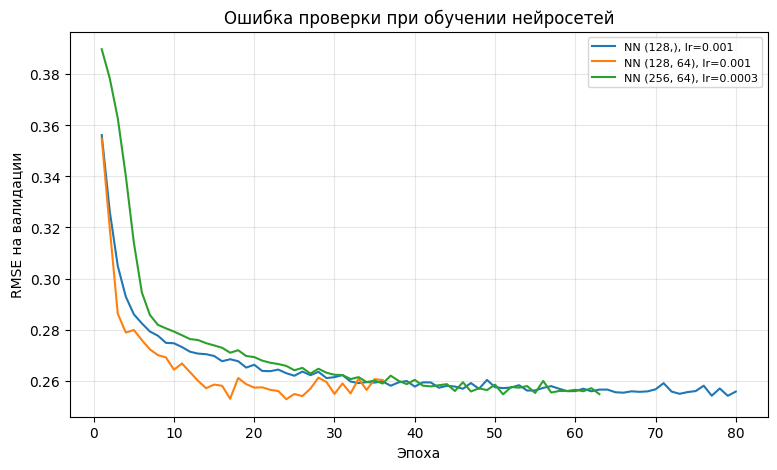

In [14]:
# Посмотрим на обучение нейросетей.
plt.figure(figsize=(9, 5))
for name, history in histories.items():
    plt.plot(history.epoch, history.valid_rmse, label=name)
plt.xlabel('Эпоха')
plt.ylabel('RMSE на валидации')
plt.title('Ошибка проверки при обучении нейросетей')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

На графике показана именно валидационная ошибка, которая использовалась для ранней остановки. При отсутствии улучшения в течение 12 эпох обучение прекращается; перед сравнением восстановлены веса лучшей эпохи по RMSE. Поскольку ошибка соответствия и качество поиска — разные задачи, сеть с наименьшей RMSE может не иметь лучший Recall@5.

## 7. Тестирование и демонстрация поиска

In [15]:
# Проверим выбранную модель на отложенных изображениях.
holdout_scores = regression_metrics(y_holdout, predict_score(best_model, X_holdout))
holdout_ranking = ranking_metrics(best_model, holdout_pairs)
display(pd.DataFrame([{'Модель': best_name, **holdout_scores, **holdout_ranking}]))
holdout_baseline = regression_metrics(y_holdout, np.full(len(y_holdout), y_train.mean()))
display(pd.DataFrame([holdout_baseline], index=['Среднее обучения']))

,Модель,RMSE,MAE,Recall@1,Recall@5,Запросов
0,"NN (128, 64), lr=0.001",0.24225,0.18352,0.111111,0.208333,72


,RMSE,MAE
Среднее обучения,0.277982,0.227679


Это первая оценка выбранной модели на отложенной части. Ни её признаки, ни её оценки не участвовали в обучении TF-IDF, масштабирования, регрессоров и выборе настроек. Признаки изображений получены внешней предобученной ResNet50. Далее проверим поиск в отдельной галерее `test_images`.

In [16]:
# Подготовим поиск среди разрешённых тестовых изображений.
def search_image(query, show=True):
    if restricted_query(query):
        if show:
            print(DISCLAIMER)
        return None
    text = text_vectorizer.transform([str(query)]).toarray().astype('float32')
    if not text.any():
        if show:
            print('В запросе нет слов из обученного словаря. Попробуйте другое описание.')
        return None
    features = np.concatenate([
        scaled_test_images, np.repeat(text, len(gallery_names), axis=0)
    ], axis=1)
    scores = predict_score(best_model, features)
    order = np.argsort(-scores)
    image_name = gallery_names[order[0]]
    result = {'image': image_name, 'score': float(scores[order[0]]),
              'top5': [gallery_names[i] for i in order[:5]]}
    if show:
        with Image.open(DATA_DIR / 'test_images' / image_name) as image:
            plt.figure(figsize=(7, 5))
            plt.imshow(image.convert('RGB'))
        plt.axis('off')
        plt.title(f'Оценка соответствия: {result["score"]:.3f}')
        plt.show()
        print('Запрос:', query)
        print('Изображение:', image_name)
    return result

search_image('A child is playing in a park')
search_image('A 12-year-old person with a bicycle')

This image is unavailable in your country in compliance with local laws.
This image is unavailable in your country in compliance with local laws.


Для запросов, связанных с детьми, функция выдаёт установленный в задании дисклеймер и не выполняет ранжирование. Она также не возвращает изображения из исключённой галереи. Оценка модели находится в диапазоне 0–1, но не интерпретируется как гарантированная вероятность.

In [17]:
# Оценим поиск по всем разрешённым тестовым запросам.
test_search_rows = []
for row in safe_test_queries.itertuples():
    result = search_image(row.query_text, show=False)
    test_search_rows.append({
        'query_id': row.query_id, 'query_text': row.query_text, 'expected': row.image,
        'found': result['image'] if result else None,
        'score': result['score'] if result else np.nan,
        'hit1': result is not None and result['image'] == row.image,
        'hit5': result is not None and row.image in result['top5']
    })
test_search = pd.DataFrame(test_search_rows)
print('Безопасных запросов:', len(test_search))
print('Изображений в галерее:', len(gallery_names))
print('Recall@1:', round(test_search.hit1.mean(), 3))
print('Recall@5:', round(test_search.hit5.mean(), 3))
print('Случайный ориентир Recall@1:', round(1 / len(gallery_names), 3))
print('Случайный ориентир Recall@5:', round(min(5, len(gallery_names)) / len(gallery_names), 3))

# Выберем 10 случайных запросов для визуального сравнения.
demo_queries = test_search.sample(10, random_state=RANDOM_STATE).reset_index(drop=True)
display(demo_queries[['query_text', 'expected', 'found', 'score', 'hit1', 'hit5']])

Безопасных запросов: 280
Изображений в галерее: 56
Recall@1: 0.054
Recall@5: 0.189
Случайный ориентир Recall@1: 0.018
Случайный ориентир Recall@5: 0.089


,query_text,expected,found,score,hit1,hit5
0,The man in the backpack looks to his left .,2461990494_c5ece064cc.jpg,3287969199_08e775d896.jpg,0.313060,False,False
1,Two dogs fighting over a toy in the snow .,3154152744_4e93ec8a62.jpg,3514297698_0512623955.jpg,0.659392,False,False
2,Two small white dogs are in a yard chasing a r...,381514859_b40418d9c3.jpg,957682378_46c3b07bcd.jpg,0.197223,False,False
3,The shoppers are walking in a store .,440190907_bf8b7ba8ef.jpg,3044359043_627488ddf0.jpg,0.307142,False,True
4,"Two people , one in blue and one in red , stan...",3330333217_1a69497a74.jpg,404850242_3a55a4c874.jpg,0.349867,False,False
5,Two dogs stand in the brown grass .,1429546659_44cb09cbe2.jpg,957682378_46c3b07bcd.jpg,0.577782,False,False
6,A blue bird flying over water .,3287969199_08e775d896.jpg,3287969199_08e775d896.jpg,0.545884,True,True
7,Little brown and white dog running on the side...,3488087117_2719647989.jpg,3514297698_0512623955.jpg,0.442418,False,True
8,A long-haired brown and white dog carries a sn...,3262849619_0bc4f88ef9.jpg,3514297698_0512623955.jpg,0.527427,False,False
9,Cyclists are leaping into the air whilst being...,3356748019_2251399314.jpg,3287969199_08e775d896.jpg,0.233925,False,True


Внешние тестовые запросы содержат исходное изображение описания, но не оценки всех возможных пар. Поэтому RMSE для всей галереи здесь посчитать нельзя. Recall@1 и Recall@5 показывают попадание именно исходной фотографии: другая подходящая фотография может быть отмечена как промах, хотя визуально соответствует запросу. Тестовые результаты не используем для повторного выбора модели.

Запрос: The man in the backpack looks to his left .


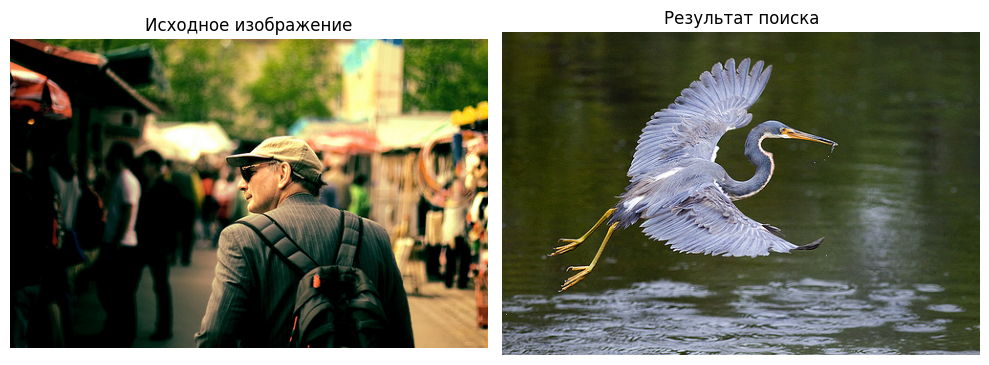

Оценка: 0.313 Точное совпадение: False


In [18]:
# Посмотрим результат запроса 1.
row = demo_queries.iloc[0]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

Запрос описывает мужчину с рюкзаком, смотрящего влево. Найдена птица над водой: ни человек, ни рюкзак не совпали. Это явная ошибка определения сюжета; оценка 0.313 не должна восприниматься как уверенность в правильном ответе.

Запрос: Two dogs fighting over a toy in the snow .


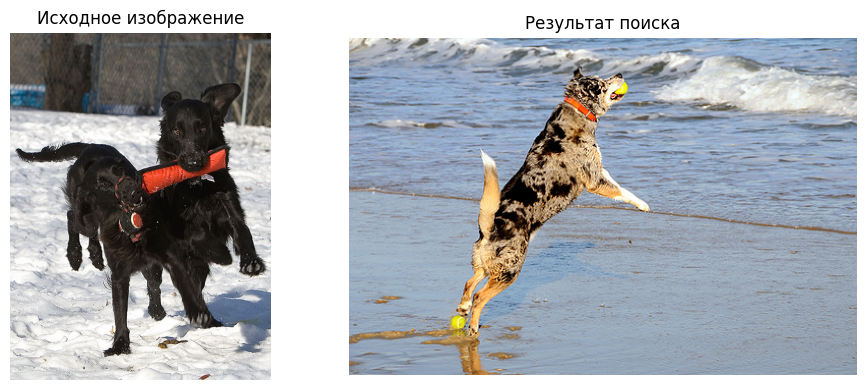

Оценка: 0.659 Точное совпадение: False


In [19]:
# Посмотрим результат запроса 2.
row = demo_queries.iloc[1]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

В выдаче тоже есть собака и предмет у неё во рту, но вместо двух собак, спорящих за игрушку на снегу, показана одна собака у воды. Общий объект найден, количество животных и условия сцены потеряны.

Запрос: Two small white dogs are in a yard chasing a red ball .


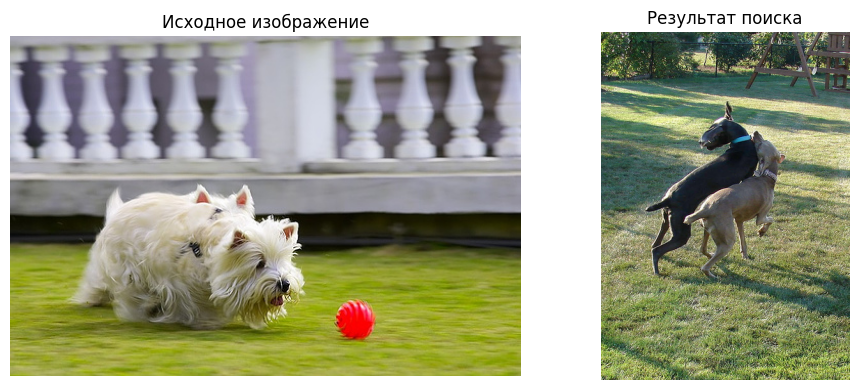

Оценка: 0.197 Точное совпадение: False


In [20]:
# Посмотрим результат запроса 3.
row = demo_queries.iloc[2]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

Модель нашла двух собак на траве, что частично соответствует запросу. Однако собаки другого цвета, красного мяча в результате нет. Поиск лучше учитывает общий тип сцены, чем мелкие предметы и признаки.

Запрос: The shoppers are walking in a store .


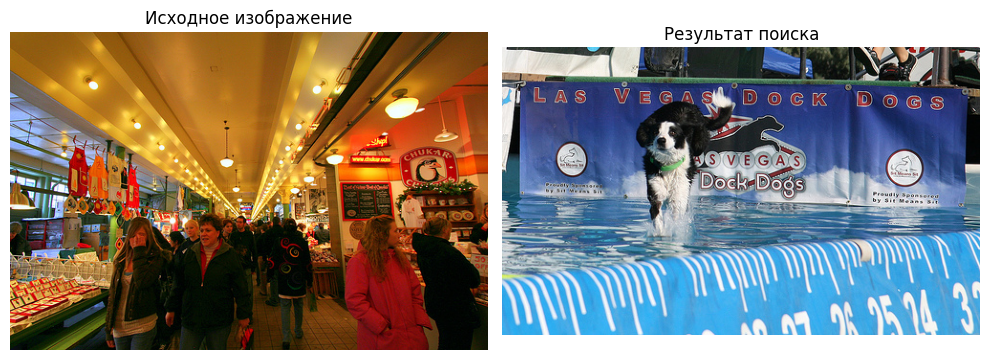

Оценка: 0.307 Точное совпадение: False


In [21]:
# Посмотрим результат запроса 4.
row = demo_queries.iloc[3]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

Вместо покупателей в магазине найдена собака, прыгающая в воду. Первый результат не соответствует запросу. Исходная фотография оказалась в первой пятёрке, но функция, возвращающая только максимум, её не показала.

Запрос: Two people , one in blue and one in red , stand in front of a building .


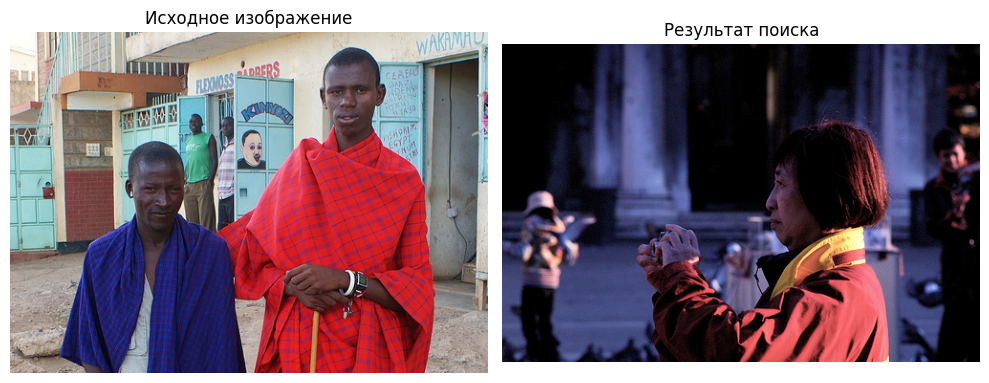

Оценка: 0.35 Точное совпадение: False


In [22]:
# Посмотрим результат запроса 5.
row = demo_queries.iloc[4]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

Найдена фотография человека в красной одежде, но число людей, синяя одежда второго человека и положение перед зданием не совпали. Часть визуальных признаков похожа, полного соответствия сцене нет.

Запрос: Two dogs stand in the brown grass .


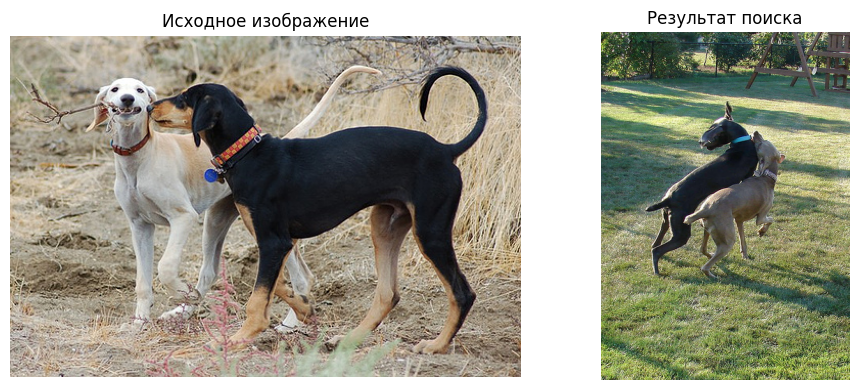

Оценка: 0.578 Точное совпадение: False


In [23]:
# Посмотрим результат запроса 6.
row = demo_queries.iloc[5]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

В выдаче два животных на траве, поэтому основной объект запроса учтён. Однако вместо спокойно стоящих собак на сухой траве показаны играющие собаки на зелёной лужайке. Модель теряет различия в действии и окружении.

Запрос: A blue bird flying over water .


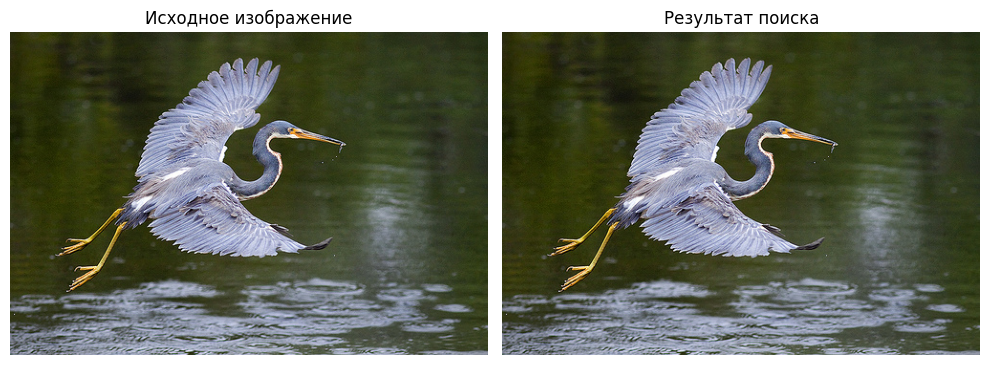

Оценка: 0.546 Точное совпадение: True


In [24]:
# Посмотрим результат запроса 7.
row = demo_queries.iloc[6]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

Получено точное совпадение: найдена исходная фотография голубовато-серой птицы, летящей над водой. В этом примере совпадают объект, действие и фон. Это удачный результат поиска.

Запрос: Little brown and white dog running on the sidewalk .


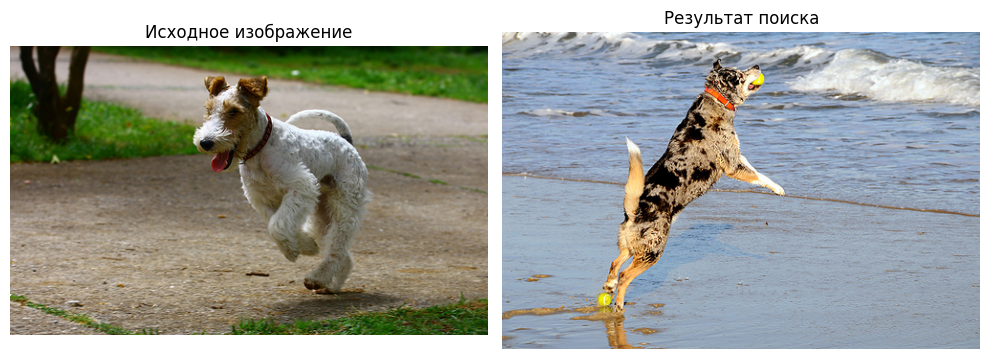

Оценка: 0.442 Точное совпадение: False


In [25]:
# Посмотрим результат запроса 8.
row = demo_queries.iloc[7]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

Общий объект совпал — собака, но вместо маленькой коричнево-белой собаки на дорожке найдена другая собака у воды с мячом. Исходная фотография есть в первой пятёрке, однако на первое место модель поставила менее подходящую сцену.

Запрос: A long-haired brown and white dog carries a snowball in his mouth .


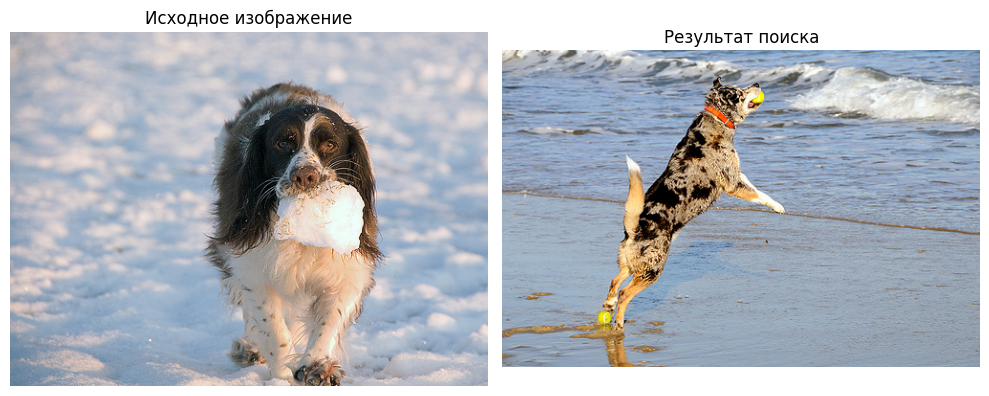

Оценка: 0.527 Точное совпадение: False


In [26]:
# Посмотрим результат запроса 9.
row = demo_queries.iloc[8]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

Найдена собака с предметом во рту, но внешность животного и предмет не совпадают: вместо длинношёрстной собаки со снежком показана короткошёрстная собака с мячом у воды. Это частичное соответствие, а не точное выполнение запроса.

Запрос: Cyclists are leaping into the air whilst being watched by spectators .


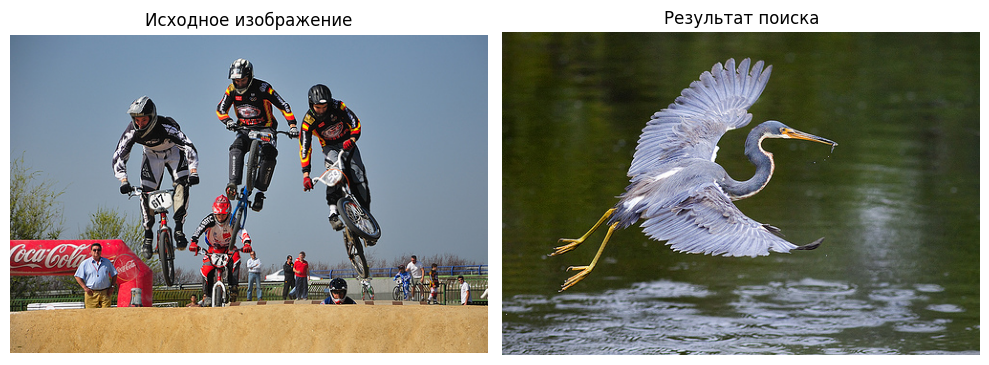

Оценка: 0.234 Точное совпадение: False


In [27]:
# Посмотрим результат запроса 10.
row = demo_queries.iloc[9]
print('Запрос:', row.query_text)
result = search_image(row.query_text, show=False)
if result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, name, title in zip(axes, [row.expected, result['image']],
                               ['Исходное изображение', 'Результат поиска']):
        with Image.open(DATA_DIR / 'test_images' / name) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Оценка:', round(result['score'], 3), 'Точное совпадение:', row.hit1)

На запрос о прыгающих велосипедистах модель вернула летящую птицу. Сходство есть только на уровне движения в воздухе; велосипедов и зрителей в результате нет. Исходная фотография попала в первую пятёрку, но первое место оказалось ошибочным.

## 8. Выводы

Исследовали 5822 экспертно размеченные пары и 47 830 пар с краудсорсинговой разметкой. Пропусков и полных дубликатов в исходных таблицах нет. Для обучения выбрали среднюю экспертную оценку, приведённую к шкале 0–1.

После фильтрации осталось 3179 пар с 705 оцениваемыми изображениями. По собственным описаниям исключены 290 обучающих и 44 тестовых изображений. Фильтр учитывает слова и явно указанный возраст меньше 16 лет, но не доказывает отсутствие детей на оставшихся фотографиях.

Изображение представлено 2048 признаками ResNet50, текст — 512 признаками TF-IDF. Вектор пары содержит 2560 признаков. Выборки разделены по изображениям; словарь и масштабирование обучены только на тренировочной части.

Лучше всего на валидации показала себя полносвязная сеть с двумя скрытыми слоями — 128 и 64 нейрона, ReLU и сигмоидой на выходе. При шаге Adam 0.001 и регуляризации 0.001 её Recall@5 составил 0.300, RMSE — 0.2528. Обычная линейная регрессия показала высокую ошибку. Ridge уменьшила ошибку, но линейная оценка на конкатенации не умеет менять ранжирование фотографий по смыслу запроса.

На отложенных фотографиях выбранная сеть получила **RMSE 0.2422 и MAE 0.1835**. RMSE постоянного предсказания среднего равна 0.2780; сеть лучше этого ориентира. Recall@5 по известным релевантным парам отложенной части — 0.208 на 72 запросах.

В отдельной тестовой галерее после фильтра осталось 56 изображений и 280 запросов. **Recall@1 — 0.054, Recall@5 — 0.189**. Для равномерного случайного выбора ориентиры составляют 0.018 и 0.089 соответственно. Сравнение показывает результат выше случайного ориентира, но не доказывает высокое качество сервиса: пять описаний одной фотографии зависимы между собой, а галерея небольшая.

В десяти случайных примерах получено одно точное совпадение. В некоторых остальных случаях правильно найден общий объект, но не его цвет, количество, окружение или действие. Есть явные промахи, когда вместо людей возвращаются собаки или птица. Оценки в диапазоне 0–1 не являются калиброванными вероятностями.

Демонстрационная версия технически реализована: запрос преобразуется в признаки, все разрешённые фотографии ранжируются, функция возвращает изображение с максимальной оценкой. Для запрещённых запросов выводится дисклеймер. Однако **качества этой версии недостаточно для запуска полноценного сервиса**.

Дальнейшие шаги: собрать больше разнообразных релевантных и нерелевантных пар, проверить текстовые эмбеддинги BERT вместо TF-IDF, отдельно оценить сложные действия и отношения объектов. Правовую фильтрацию нужно дополнить проверкой изображений и согласий. Эти улучшения в текущем эксперименте не выполнялись.

### Чек-лист

- [x] Проанализированы таблицы и оба источника разметки.
- [x] Проверены пропуски, дубликаты, диапазоны оценок и наличие файлов.
- [x] Выполнено исключение контента по словарю ограничений.
- [x] Изображения векторизованы ResNet50, тексты — TF-IDF.
- [x] Выборки разделены по изображениям, преобразования обучены на тренировочной части.
- [x] Рассмотрены линейная регрессия и полносвязные нейросети с разными настройками.
- [x] Выбор модели выполнен на валидации.
- [x] Проведены отложенная проверка и поиск в отдельной тестовой галерее.
- [x] Показаны 10 запросов с результатами поиска и пояснениями.
- [x] Проверена выдача дисклеймера.
- [x] Сделаны выводы об осуществимости PoC и ограничениях.